# Predicting Prolonged ICU Stay (>7 Days) Using MIMIC-III

Research question: Can information available during the first 24 hours of an ICU stay predict whether the ICU stay will last more than 7 days?

Outcome: OUTPUT_LABEL = 1 for ICU LOS > 7 days, otherwise 0.

# 1. Setup

Requirements:
- Credentialed MIMIC-III access on PhysioNet
- Google Cloud identity linked to PhysioNet
- Google Cloud project with BigQuery enabled and billing attached
- Same Google account in Colab
Replace YOUR_GCP_PROJECT_ID below with your own billing project ID.

In [33]:
# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.cloud import bigquery

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay
)


## Authentic Google cloud. 

install Google Cloud CLI on my  laptop (Mac) with Homebrew:

#brew install --cask gcloud-cli

Also initialise gcloud #gcloud init

Google Application Default Credentials were configured before running the notebook using:

`gcloud auth application-default login`

In [34]:
# Check Google credentials
import google.auth

credentials, project = google.auth.default()

print("Credentials found:", credentials is not None)
print("Detected project:", project)

Credentials found: True
Detected project: project-c5b21340-602f-4751-84b


## Create BigQuery client

In [35]:
# Connect Python to BigQuery

from google.cloud import bigquery

PROJECT_ID = "project-c5b21340-602f-4751-84b"

client = bigquery.Client(project=PROJECT_ID)

print("BigQuery client created successfully")

BigQuery client created successfully


# 2. BigQuery extraction and Run BigQuery and load the small result into pandas

Selected MIMIC-III lab ITEMIDs:
- 50912 Creatinine
- 51006 Urea Nitrogen (BUN)
- 50983 Sodium
- 50971 Potassium
- 50931 Glucose
- 51222 Hemoglobin
- 51301 White Blood Cells
- 51265 Platelet Count
The SQL:
1. keeps the first ICU stay per patient,
2. keeps adults,
3. creates the >7-day outcome,
4. restricts labs to the first 24 hours,
5. keeps only selected lab tests,
6. calculates min/max/mean for each lab,
7. returns one row per ICU stay.

In [36]:

client = bigquery.Client(project="project-c5b21340-602f-4751-84b")

QUERY = """
WITH first_icu AS (
  SELECT
    subject_id, hadm_id, icustay_id, intime, outtime, los,
    ROW_NUMBER() OVER (
      PARTITION BY subject_id
      ORDER BY intime
    ) AS rn
  FROM `physionet-data.mimiciii_clinical.icustays`
),

cohort AS (
  SELECT
    i.subject_id,
    i.hadm_id,
    i.icustay_id,
    i.intime,
    i.outtime,
    i.los,
    p.gender,
    a.admission_type,
    CASE
      WHEN DATE_DIFF(DATE(i.intime), DATE(p.dob), YEAR) > 89 THEN 90
      ELSE DATE_DIFF(DATE(i.intime), DATE(p.dob), YEAR)
    END AS age,
    CASE WHEN i.los > 7 THEN 1 ELSE 0 END AS output_label
  FROM first_icu i
  JOIN `physionet-data.mimiciii_clinical.patients` p
    ON i.subject_id = p.subject_id
  JOIN `physionet-data.mimiciii_clinical.admissions` a
    ON i.subject_id = a.subject_id
   AND i.hadm_id = a.hadm_id
  WHERE i.rn = 1
    AND i.los IS NOT NULL
),

adult_cohort AS (
  SELECT *
  FROM cohort
  WHERE age >= 18
),

labs_24h AS (
  SELECT
    c.icustay_id,
    l.itemid,
    l.valuenum
  FROM adult_cohort c
  JOIN `physionet-data.mimiciii_clinical.labevents` l
    ON c.subject_id = l.subject_id
   AND c.hadm_id = l.hadm_id
  WHERE l.valuenum IS NOT NULL
    AND l.itemid IN (50912,51006,50983,50971,50931,51222,51301,51265)
    AND l.charttime >= c.intime
    AND l.charttime < TIMESTAMP_ADD(c.intime, INTERVAL 24 HOUR)
),

lab_features AS (
  SELECT
    icustay_id,

    MIN(IF(itemid=50912, valuenum, NULL)) AS creatinine_min,
    MAX(IF(itemid=50912, valuenum, NULL)) AS creatinine_max,
    AVG(IF(itemid=50912, valuenum, NULL)) AS creatinine_mean,

    MIN(IF(itemid=51006, valuenum, NULL)) AS bun_min,
    MAX(IF(itemid=51006, valuenum, NULL)) AS bun_max,
    AVG(IF(itemid=51006, valuenum, NULL)) AS bun_mean,

    MIN(IF(itemid=50983, valuenum, NULL)) AS sodium_min,
    MAX(IF(itemid=50983, valuenum, NULL)) AS sodium_max,
    AVG(IF(itemid=50983, valuenum, NULL)) AS sodium_mean,

    MIN(IF(itemid=50971, valuenum, NULL)) AS potassium_min,
    MAX(IF(itemid=50971, valuenum, NULL)) AS potassium_max,
    AVG(IF(itemid=50971, valuenum, NULL)) AS potassium_mean,

    MIN(IF(itemid=50931, valuenum, NULL)) AS glucose_min,
    MAX(IF(itemid=50931, valuenum, NULL)) AS glucose_max,
    AVG(IF(itemid=50931, valuenum, NULL)) AS glucose_mean,

    MIN(IF(itemid=51222, valuenum, NULL)) AS hemoglobin_min,
    MAX(IF(itemid=51222, valuenum, NULL)) AS hemoglobin_max,
    AVG(IF(itemid=51222, valuenum, NULL)) AS hemoglobin_mean,

    MIN(IF(itemid=51301, valuenum, NULL)) AS wbc_min,
    MAX(IF(itemid=51301, valuenum, NULL)) AS wbc_max,
    AVG(IF(itemid=51301, valuenum, NULL)) AS wbc_mean,

    MIN(IF(itemid=51265, valuenum, NULL)) AS platelets_min,
    MAX(IF(itemid=51265, valuenum, NULL)) AS platelets_max,
    AVG(IF(itemid=51265, valuenum, NULL)) AS platelets_mean

  FROM labs_24h
  GROUP BY icustay_id
)

SELECT
  c.subject_id,
  c.hadm_id,
  c.icustay_id,
  c.age,
  c.gender,
  c.admission_type,
  c.los,
  c.output_label,

  lf.creatinine_min,
  lf.creatinine_max,
  lf.creatinine_mean,
  lf.bun_min,
  lf.bun_max,
  lf.bun_mean,
  lf.sodium_min,
  lf.sodium_max,
  lf.sodium_mean,
  lf.potassium_min,
  lf.potassium_max,
  lf.potassium_mean,
  lf.glucose_min,
  lf.glucose_max,
  lf.glucose_mean,
  lf.hemoglobin_min,
  lf.hemoglobin_max,
  lf.hemoglobin_mean,
  lf.wbc_min,
  lf.wbc_max,
  lf.wbc_mean,
  lf.platelets_min,
  lf.platelets_max,
  lf.platelets_mean

FROM adult_cohort c
LEFT JOIN lab_features lf
  ON c.icustay_id = lf.icustay_id
ORDER BY c.subject_id
"""

query_job = client.query(QUERY)
df_model = query_job.to_dataframe()

print("Rows:", len(df_model))
print("Columns:", len(df_model.columns))

df_model.head()



/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Rows: 38536
Columns: 32


,subject_id,hadm_id,icustay_id,age,gender,admission_type,los,output_label,creatinine_min,creatinine_max,...,glucose_mean,hemoglobin_min,hemoglobin_max,hemoglobin_mean,wbc_min,wbc_max,wbc_mean,platelets_min,platelets_max,platelets_mean
0,3,145834,211552,76,M,EMERGENCY,6.0646,0,2.4,2.5,...,223.25,7.8,10.4,9.025,11.3,24.4,18.40,190.0,359.0,255.25
1,4,185777,294638,48,F,EMERGENCY,1.6785,0,0.5,0.5,...,183.00,10.6,10.6,10.600,9.7,9.7,9.70,201.0,201.0,201.00
2,6,107064,228232,66,F,ELECTIVE,3.6729,0,10.0,10.0,...,181.00,9.2,9.2,9.200,10.6,10.6,10.60,330.0,330.0,330.00
3,9,150750,220597,41,M,EMERGENCY,5.3231,0,1.4,1.4,...,151.00,12.9,12.9,12.900,13.7,13.7,13.70,249.0,249.0,249.00
4,11,194540,229441,50,F,EMERGENCY,1.5844,0,0.7,0.7,...,127.50,12.5,12.6,12.550,9.3,12.8,11.05,243.0,258.0,250.50


# 3. Save the extracted feature table
After one successful query, save this smaller file. In later Colab sessions we can upload only this file.

In [37]:
df_model.to_csv("prolonged_icu_features.csv", index=False)
print("Saved prolonged_icu_features.csv")

Saved prolonged_icu_features.csv


# 4. Explore the outcome

Positive samples: 5215
Negative samples: 33321
Total samples: 38536
Prevalence: 0.135


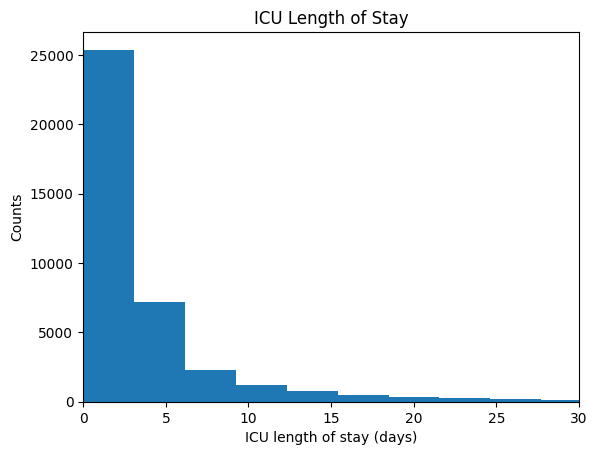

In [38]:
df_model = df_model.rename(columns={"output_label":"OUTPUT_LABEL"})

print("Positive samples:", (df_model.OUTPUT_LABEL == 1).sum())
print("Negative samples:", (df_model.OUTPUT_LABEL == 0).sum())
print("Total samples:", len(df_model))
print(
    "Prevalence: %.3f"
    % (df_model.OUTPUT_LABEL.sum()/len(df_model))
)

plt.hist(df_model.los, bins=50)
plt.xlim([0,30])
plt.xlabel("ICU length of stay (days)")
plt.ylabel("Counts")
plt.title("ICU Length of Stay")
plt.show()

# 5.Select model features

In [39]:
exclude_cols = [
    "subject_id",
    "hadm_id",
    "icustay_id",
    "los",
    "OUTPUT_LABEL"
]

feature_cols = [
    c for c in df_model.columns
    if c not in exclude_cols
]

print(feature_cols)

['age', 'gender', 'admission_type', 'creatinine_min', 'creatinine_max', 'creatinine_mean', 'bun_min', 'bun_max', 'bun_mean', 'sodium_min', 'sodium_max', 'sodium_mean', 'potassium_min', 'potassium_max', 'potassium_mean', 'glucose_min', 'glucose_max', 'glucose_mean', 'hemoglobin_min', 'hemoglobin_max', 'hemoglobin_mean', 'wbc_min', 'wbc_max', 'wbc_mean', 'platelets_min', 'platelets_max', 'platelets_mean']


# 6.Train / validation / test split

In [41]:
df_model = df_model.sample(
    n=len(df_model),
    random_state=42
).reset_index(drop=True)

df_valid_test = df_model.sample(
    frac=0.30,
    random_state=42
)

df_test = df_valid_test.sample(
    frac=0.5,
    random_state=42
)

df_valid = df_valid_test.drop(df_test.index)
df_train_all = df_model.drop(df_valid_test.index)

print(
    "Train all prevalence(n = %d):" % len(df_train_all),
    df_train_all.OUTPUT_LABEL.mean()
)
print(
    "Valid prevalence(n = %d):" % len(df_valid),
    df_valid.OUTPUT_LABEL.mean()
)
print(
    "Test prevalence(n = %d):" % len(df_test),
    df_test.OUTPUT_LABEL.mean()
)


Train all prevalence(n = 26975): 0.1347914735866543
Valid prevalence(n = 5781): 0.13527071440927174
Test prevalence(n = 5780): 0.1378892733564014


# 7. Balance the training set only

In [42]:
rows_pos = df_train_all.OUTPUT_LABEL == 1
df_train_pos = df_train_all.loc[rows_pos]
df_train_neg = df_train_all.loc[~rows_pos]

if len(df_train_neg) >= len(df_train_pos):
    df_train = pd.concat([
        df_train_pos,
        df_train_neg.sample(
            n=len(df_train_pos),
            random_state=42
        )
    ])
else:
    df_train = pd.concat([
        df_train_neg,
        df_train_pos.sample(
            n=len(df_train_neg),
            random_state=42
        )
    ])

df_train = df_train.sample(
    n=len(df_train),
    random_state=42
).reset_index(drop=True)

print(
    "Balanced train prevalence(n = %d):" % len(df_train),
    df_train.OUTPUT_LABEL.mean()
)

Balanced train prevalence(n = 7272): 0.5


# 8.Missing values + dummy variables

In [43]:
categorical_features = ["gender", "admission_type"]

numeric_features = [
    c for c in feature_cols
    if c not in categorical_features
]

train_medians = df_train[numeric_features].median()

def preprocess(df):
    df = df.copy()

    for c in numeric_features:
        df[c] = df[c].fillna(train_medians[c])

    for c in categorical_features:
        df[c] = df[c].fillna("UNKNOWN")

    return df

df_train = preprocess(df_train)
df_valid = preprocess(df_valid)
df_test = preprocess(df_test)

df_all_features = pd.concat([
    df_train[feature_cols],
    df_valid[feature_cols],
    df_test[feature_cols]
], axis=0)

df_all_features = pd.get_dummies(
    df_all_features,
    columns=categorical_features,
    drop_first=False
)

n_train = len(df_train)
n_valid = len(df_valid)

X_train = df_all_features.iloc[:n_train].values
X_valid = df_all_features.iloc[n_train:n_train+n_valid].values
X_test = df_all_features.iloc[n_train+n_valid:].values

feature_names = df_all_features.columns

y_train = df_train.OUTPUT_LABEL.values
y_valid = df_valid.OUTPUT_LABEL.values
y_test = df_test.OUTPUT_LABEL.values

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() #scaling fixes the Logistic Regression convergence warning

X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

# 9.evaluation functions

In [45]:
def calc_accuracy(y_actual, y_pred, thresh):
    return (
        sum((y_pred >= thresh) & (y_actual == 1)) +
        sum((y_pred < thresh) & (y_actual == 0))
    ) / len(y_actual)

def calc_recall(y_actual, y_pred, thresh):
    denom = sum(y_actual == 1)
    return 0 if denom == 0 else sum((y_pred >= thresh) & (y_actual == 1)) / denom


def calc_precision(y_actual, y_pred, thresh):
    denom = sum(y_pred >= thresh)
    return 0 if denom == 0 else sum((y_pred >= thresh) & (y_actual == 1)) / denom

def calc_specificity(y_actual, y_pred, thresh):
    denom = sum(y_actual == 0)
    return 0 if denom == 0 else sum((y_pred < thresh) & (y_actual == 0)) / denom
    
def calc_prevalence(y_actual):
    return sum(y_actual == 1) / len(y_actual)

# 10.Logistic Regression baseline

In [46]:
clf = LogisticRegression(
    C=0.001,
    penalty="l2",
    random_state=42,
    max_iter=2000
)

clf.fit(X_train, y_train)

y_train_preds = clf.predict_proba(X_train)[:,1]
y_valid_preds = clf.predict_proba(X_valid)[:,1]

auc_train = roc_auc_score(y_train, y_train_preds)
auc_valid = roc_auc_score(y_valid, y_valid_preds)

print("Train AUC: %.3f" % auc_train)
print("Valid AUC: %.3f" % auc_valid)

from sklearn.metrics import average_precision_score

pr_auc_valid = average_precision_score(
    y_valid,
    y_valid_preds
)

print(
    'Validation PR-AUC: %.3f'
    % pr_auc_valid
)

thresholds = [
    0.3,
    0.4,
    0.5,
    0.6,
    0.7
]

for thresh in thresholds:
    
    print('\nThreshold:', thresh)
    
    print(
        'Recall: %.3f' %
        calc_recall(
            y_valid,
            y_valid_preds,
            thresh
        )
    )
    
    print(
        'Precision: %.3f' %
        calc_precision(
            y_valid,
            y_valid_preds,
            thresh
        )
    )
    
    print(
        'Specificity: %.3f' %
        calc_specificity(
            y_valid,
            y_valid_preds,
            thresh
        )
    )





Train AUC: 0.665
Valid AUC: 0.678
Validation PR-AUC: 0.236

Threshold: 0.3
Recall: 1.000
Precision: 0.136
Specificity: 0.004

Threshold: 0.4
Recall: 0.918
Precision: 0.147
Specificity: 0.170

Threshold: 0.5
Recall: 0.596
Precision: 0.238
Specificity: 0.702

Threshold: 0.6
Recall: 0.221
Precision: 0.291
Specificity: 0.916

Threshold: 0.7
Recall: 0.054
Precision: 0.273
Specificity: 0.978


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# 11.ROC curve

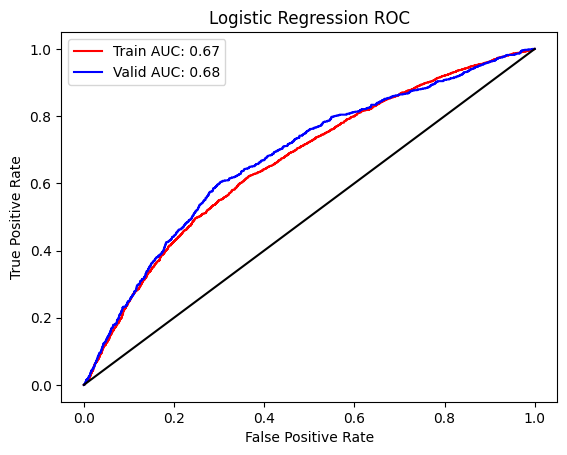

In [50]:
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_preds)
fpr_valid, tpr_valid, _ = roc_curve(y_valid, y_valid_preds)

plt.plot(fpr_train, tpr_train, "r-", label="Train AUC: %.2f" % auc_train)
plt.plot(fpr_valid, tpr_valid, "b-", label="Valid AUC: %.2f" % auc_valid)
plt.plot([0,1],[0,1],"-k")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC")
plt.legend()
plt.show()

# 12. Tune Logistic Regression C

In [51]:
#Cs = [0.0001,0.0003,0.001,0.003,0.01,0.03,0.1]
Cs = [0.0001,0.001,0.01,0.1,1,10]

train_aucs = np.zeros(len(Cs))
valid_aucs = np.zeros(len(Cs))

for ii in range(len(Cs)):
    
    C = Cs[ii]
    
    clf_temp = LogisticRegression(
        C = C,
        penalty = 'l2',
        solver = 'lbfgs',
        random_state = 42,
        max_iter = 5000
    )
    
    clf_temp.fit(X_train, y_train)
 
    y_train_temp = clf_temp.predict_proba(X_train)[:,1]
    y_valid_temp = clf_temp.predict_proba(X_valid)[:,1]
    
    train_aucs[ii] = roc_auc_score(
        y_train,
        y_train_temp
    )
    
    valid_aucs[ii] = roc_auc_score(
        y_valid,
        y_valid_temp
    )
    
    print(
        'C = %.4f, Train AUC = %.3f, Valid AUC = %.3f'
        % (
            C,
            train_aucs[ii],
            valid_aucs[ii]
        )
    )

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

C = 0.0001, Train AUC = 0.656, Valid AUC = 0.662
C = 0.0010, Train AUC = 0.665, Valid AUC = 0.678
C = 0.0100, Train AUC = 0.667, Valid AUC = 0.683
C = 0.1000, Train AUC = 0.668, Valid AUC = 0.684
C = 1.0000, Train AUC = 0.669, Valid AUC = 0.684
C = 10.0000, Train AUC = 0.669, Valid AUC = 0.684


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# 13.Final test evaluation

In [52]:
best_C = 1
print("Best C:", best_C)

clf_final = LogisticRegression(
    C=best_C,
    penalty="l2",
    random_state=42,
    max_iter=2000
)

clf_final.fit(X_train, y_train)

y_test_preds = clf_final.predict_proba(X_test)[:,1]
auc_test = roc_auc_score(y_test, y_test_preds)
pr_auc_test = average_precision_score(y_test, y_test_preds)


print("Test ROC-AUC: %.3f" % auc_test)
print("Test PR-AUC: %.3f" % pr_auc_test)
print("Test accuracy: %.3f" % calc_accuracy(y_test, y_test_preds, 0.5))
print("Test recall: %.3f" % calc_recall(y_test, y_test_preds, 0.5))
print("Test precision: %.3f" % calc_precision(y_test, y_test_preds, 0.5))
print("Test specificity: %.3f" % calc_specificity(y_test, y_test_preds, 0.5))
print("Number of iterations used for convergence:",clf_final.n_iter_)

Best C: 1
Test ROC-AUC: 0.662
Test PR-AUC: 0.228
Test accuracy: 0.673
Test recall: 0.568
Test precision: 0.226
Test specificity: 0.689
Number of iterations used for convergence: [72]


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# 14. confusion matrix

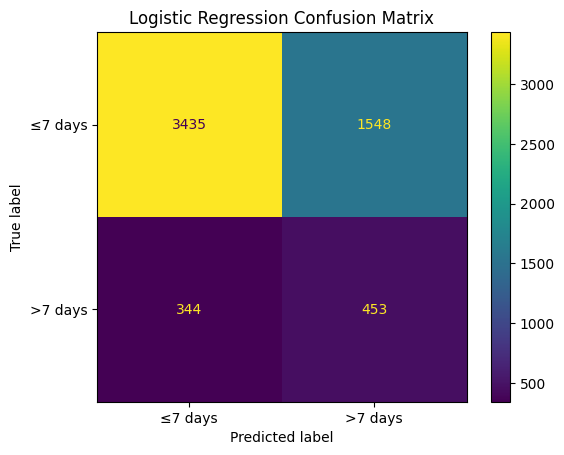

In [53]:
test_binary = (y_test_preds >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_binary,
    display_labels=["≤7 days",">7 days"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

# 15.Logistic Regression feature coefficients

In [54]:
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": clf_final.coef_[0]
})

print("Top positive coefficients")
display(coef_df.sort_values("coefficient", ascending=False).head(10))

print("Top negative coefficients")
display(coef_df.sort_values("coefficient", ascending=True).head(10))

Top positive coefficients


,feature,coefficient
4,bun_min,0.502027
20,wbc_max,0.446656
2,creatinine_max,0.432064
8,sodium_max,0.387843
15,glucose_mean,0.363314
18,hemoglobin_mean,0.324976
19,wbc_min,0.307089
6,bun_mean,0.288572
12,potassium_mean,0.243847
23,platelets_max,0.239091


Top negative coefficients


,feature,coefficient
5,bun_max,-0.551588
1,creatinine_min,-0.535869
21,wbc_mean,-0.526802
16,hemoglobin_min,-0.500198
10,potassium_min,-0.346280
9,sodium_mean,-0.342491
22,platelets_min,-0.310948
14,glucose_max,-0.213331
27,admission_type_ELECTIVE,-0.104027
13,glucose_min,-0.057082


# 16. Visualise coefficients

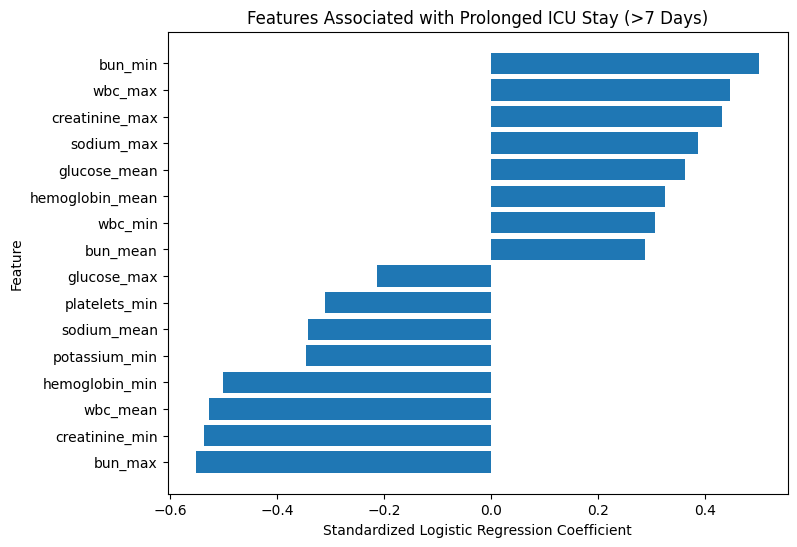

In [55]:
coef_sorted = coef_df.sort_values(
    "coefficient",
    ascending=False
)

top_features = pd.concat([
    coef_sorted.head(8),
    coef_sorted.tail(8)
])

top_features = top_features.sort_values(
    "coefficient"
)

plt.figure(figsize=(8,6))

plt.barh(
    top_features.feature,
    top_features.coefficient
)

plt.xlabel(
    "Standardized Logistic Regression Coefficient"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Features Associated with Prolonged ICU Stay (>7 Days)"
)

plt.show()

# 17.Random forest

In [56]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_valid_preds = rf.predict_proba(X_valid)[:,1]
rf_test_preds = rf.predict_proba(X_test)[:,1]

rf_valid_auc = roc_auc_score(y_valid, rf_valid_preds)
rf_test_auc = roc_auc_score(y_test, rf_test_preds)
rf_test_pr_auc = average_precision_score(y_test, rf_test_preds)

print("Random Forest Valid AUC: %.3f" % rf_valid_auc)
print("Random Forest Test ROC-AUC: %.3f" % rf_test_auc)
print("Random Forest Test PR-AUC: %.3f" % rf_test_pr_auc)

Random Forest Valid AUC: 0.712
Random Forest Test ROC-AUC: 0.694
Random Forest Test PR-AUC: 0.266


# 18. Comparision between two models

In [57]:
comparison = pd.DataFrame({
    "Model":["Logistic Regression","Random Forest"],
    "Validation ROC-AUC":[valid_aucs.max(), rf_valid_auc],
    "Test ROC-AUC":[auc_test, rf_test_auc],
    "Test PR-AUC":[pr_auc_test, rf_test_pr_auc]
})

display(comparison)

,Model,Validation ROC-AUC,Test ROC-AUC,Test PR-AUC
0,Logistic Regression,0.684101,0.662308,0.227670
1,Random Forest,0.712303,0.693598,0.266306
